# Task 2 – Heart Disease Prediction System
**🔗 Live Deployment Link:** 

**Student Name:** Asna Aqeel

 **Reg. No:** SP24-BSE-016

## Selected 4 input attributes
| Attribute | Meaning | Type |
|---|---|---|
| `Sex` | Patient sex | categorical → label-encoded |
| `ChestPain` | Chest-pain type (typical, atypical, non-anginal, asymptomatic) | categorical → label-encoded |
| `MaxHR` | Maximum heart rate achieved | numeric |
| `Oldpeak` | ST depression induced by exercise relative to rest | numeric |

Target: `AHD` (angiographic heart disease: Yes / No).


## Phase 1 – Data
### Step 1: Import libraries

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
sns.set_style("whitegrid")

### Step 2: Data collection
The Cleveland subset of the UCI Heart Disease data (303 rows, 13 attributes + diagnosis) is stored in `heart.csv`.

In [6]:
df_full = pd.read_csv("heart.csv", index_col=0)
print("Full dataset shape:", df_full.shape)
df_full.head()

Full dataset shape: (303, 14)


,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


### Step 3: Select only 4 input attributes (assignment constraint)
First a small experiment: compare candidate 4-attribute subsets with cross-validation.

In [7]:
tmp = df_full.copy()
for col in tmp.select_dtypes(exclude="number").columns.drop("AHD"):
    tmp[col] = LabelEncoder().fit_transform(tmp[col])
y_tmp = (tmp["AHD"] == "Yes").astype(int)

candidates = [["Age","Sex","ChestPain","MaxHR"],
              ["ChestPain","MaxHR","ExAng","Oldpeak"],
              ["Sex","ChestPain","MaxHR","Oldpeak"],
              ["Age","Sex","ChestPain","ExAng"],
              ["Age","RestBP","Chol","MaxHR"]]
for cols in candidates:
    s = cross_val_score(RandomForestClassifier(random_state=0), tmp[cols], y_tmp, cv=5).mean()
    print(f"{str(cols):55s} CV acc = {s:.3f}")

['Age', 'Sex', 'ChestPain', 'MaxHR']                    CV acc = 0.726
['ChestPain', 'MaxHR', 'ExAng', 'Oldpeak']              CV acc = 0.762
['Sex', 'ChestPain', 'MaxHR', 'Oldpeak']                CV acc = 0.762
['Age', 'Sex', 'ChestPain', 'ExAng']                    CV acc = 0.719
['Age', 'RestBP', 'Chol', 'MaxHR']                      CV acc = 0.654


In [8]:
FEATURES = ["Sex", "ChestPain", "MaxHR", "Oldpeak"]     
df = df_full[FEATURES + ["AHD"]].copy()

df["Sex"] = df["Sex"].map({0: "Female", 1: "Male"})
df.head()

,Sex,ChestPain,MaxHR,Oldpeak,AHD
1,Male,typical,150,2.3,No
2,Male,asymptomatic,108,1.5,Yes
3,Male,asymptomatic,129,2.6,Yes
4,Male,nonanginal,187,3.5,No
5,Female,nontypical,172,1.4,No


### Step 4: Data understanding

In [9]:
df.info()
print()
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 1 to 303
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Sex        303 non-null    str    
 1   ChestPain  303 non-null    str    
 2   MaxHR      303 non-null    int64  
 3   Oldpeak    303 non-null    float64
 4   AHD        303 non-null    str    
dtypes: float64(1), int64(1), str(3)
memory usage: 17.3 KB



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Sex,303,2,Male,206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ChestPain,303,4,asymptomatic,144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaxHR,303.0,NaN,NaN,NaN,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
Oldpeak,303.0,NaN,NaN,NaN,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2
AHD,303,2,No,164,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
print("Missing values:\n", df.isnull().sum())
print("\nTarget distribution:\n", df["AHD"].value_counts())

Missing values:
 Sex          0
ChestPain    0
MaxHR        0
Oldpeak      0
AHD          0
dtype: int64

Target distribution:
 AHD
No     164
Yes    139
Name: count, dtype: int64


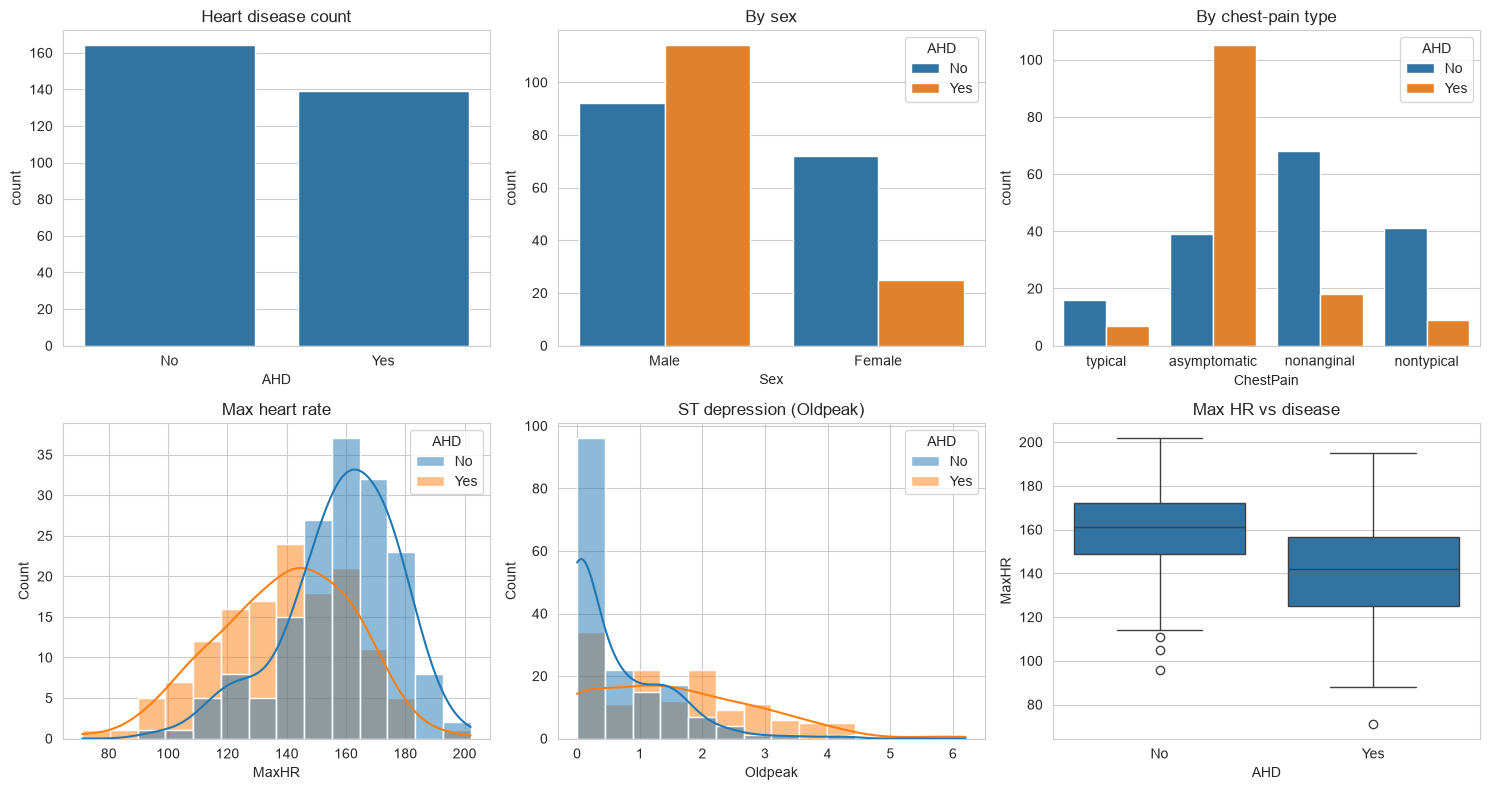

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
sns.countplot(x="AHD", data=df, ax=ax[0,0]);                      ax[0,0].set_title("Heart disease count")
sns.countplot(x="Sex", hue="AHD", data=df, ax=ax[0,1]);           ax[0,1].set_title("By sex")
sns.countplot(x="ChestPain", hue="AHD", data=df, ax=ax[0,2]);     ax[0,2].set_title("By chest-pain type")
sns.histplot(data=df, x="MaxHR", hue="AHD", kde=True, ax=ax[1,0]);   ax[1,0].set_title("Max heart rate")
sns.histplot(data=df, x="Oldpeak", hue="AHD", kde=True, ax=ax[1,1]); ax[1,1].set_title("ST depression (Oldpeak)")
sns.boxplot(x="AHD", y="MaxHR", data=df, ax=ax[1,2]);             ax[1,2].set_title("Max HR vs disease")
plt.tight_layout(); plt.show()

**Observations:** patients with *asymptomatic* chest pain, males, lower max heart rate and higher ST depression are more likely to have heart disease.

### Step 5: Data preprocessing
The 4 selected columns have no missing values. We remove duplicates (if any) and encode the target `Yes/No` → `1/0`.

In [13]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)   
df["AHD"] = df["AHD"].map({"No": 0, "Yes": 1})
print("Final shape:", df.shape)

Duplicates: 16
Final shape: (287, 5)


### Step 6: Label encoding
`Sex` and `ChestPain` are text encoded with `LabelEncoder` 

In [14]:
encoders = {}
for col in ["Sex", "ChestPain"]:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le
    print(col, "->", dict(zip(le.classes_, le.transform(le.classes_))))
df.head()

Sex -> {'Female': np.int64(0), 'Male': np.int64(1)}
ChestPain -> {'asymptomatic': np.int64(0), 'nonanginal': np.int64(1), 'nontypical': np.int64(2), 'typical': np.int64(3)}


,Sex,ChestPain,MaxHR,Oldpeak,AHD
0,1,3,150,2.3,0
1,1,0,108,1.5,1
2,1,0,129,2.6,1
3,1,1,187,3.5,0
4,0,2,172,1.4,0


### Step 7: Train–test split

In [15]:
X = df[FEATURES]
y = df["AHD"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (229, 4)  Test: (58, 4)


## Phase 2 – Training

In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree":       DecisionTreeClassifier(max_depth=4, random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=7),
    "Random Forest":       RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42),
}
for name, m in models.items():
    cv = cross_val_score(m, X_train, y_train, cv=5, scoring="accuracy").mean()
    m.fit(X_train, y_train)
    print(f"{name:20s} CV accuracy = {cv:.3f}")

Logistic Regression  CV accuracy = 0.764
Decision Tree        CV accuracy = 0.795
KNN                  CV accuracy = 0.672
Random Forest        CV accuracy = 0.803


## Phase 3 – Testing / Evaluation

In [17]:
rows = []
for name, m in models.items():
    p = m.predict(X_test)
    rows.append([name, accuracy_score(y_test,p), precision_score(y_test,p),
                 recall_score(y_test,p), f1_score(y_test,p)])
results = pd.DataFrame(rows, columns=["Model","Accuracy","Precision","Recall","F1"]).set_index("Model").round(3)
results.sort_values("Accuracy", ascending=False)

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.707,0.690,0.714,0.702
KNN,0.690,0.679,0.679,0.679
Decision Tree,0.672,0.667,0.643,0.655
Random Forest,0.672,0.655,0.679,0.667


Best model: Logistic Regression
              precision    recall  f1-score   support

  No disease       0.72      0.70      0.71        30
     Disease       0.69      0.71      0.70        28

    accuracy                           0.71        58
   macro avg       0.71      0.71      0.71        58
weighted avg       0.71      0.71      0.71        58



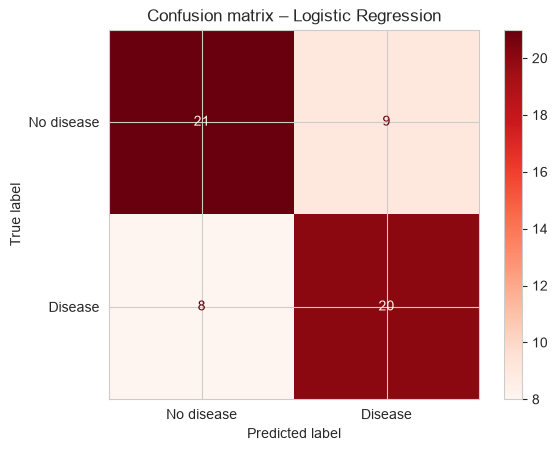

In [20]:
best_name = results["Accuracy"].idxmax()
best_model = models[best_name]
print("Best model:", best_name)
pred = best_model.predict(X_test)
print(classification_report(y_test, pred, target_names=["No disease","Disease"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No disease","Disease"]).plot(cmap="Reds")
plt.title(f"Confusion matrix – {best_name}"); plt.show()

In a medical setting **recall** (not missing sick patients) is especially important, so we look at it next to accuracy.

## Phase 4 – Deployment
### Step 1: Save the trained model

In [21]:
artifact = {"model": best_model, "encoders": encoders, "features": FEATURES, "model_name": best_name}
joblib.dump(artifact, "heart_model.pkl")
print("Saved heart_model.pkl")

Saved heart_model.pkl


### Step 2: Test loading and predicting for a new patient

In [22]:
art = joblib.load("heart_model.pkl")
new = pd.DataFrame([{
    "Sex": art["encoders"]["Sex"].transform(["Male"])[0],
    "ChestPain": art["encoders"]["ChestPain"].transform(["asymptomatic"])[0],
    "MaxHR": 120, "Oldpeak": 2.0}])[art["features"]]
prob = art["model"].predict_proba(new)[0,1]
print("Prediction:", "HEART DISEASE LIKELY" if prob >= 0.5 else "NO HEART DISEASE LIKELY", f"(probability {prob:.2f})")

Prediction: HEART DISEASE LIKELY (probability 0.93)


### Step 3: Deploy to the cloud (PythonAnywhere)
`flask_app.py`, `heart_model.pkl`, `requirements.txt` 


In [23]:
import sklearn; print('scikit-learn version used for training:', sklearn.__version__)

scikit-learn version used for training: 1.9.1


## Conclusion
Using only four inputs (sex, chest-pain type, max heart rate, ST depression) the best model (logistic regression) reaches about 70 % test accuracy, with balanced precision and recall (~0.7). Using all 13 attributes would score higher, but the assignment restricts us to 4. This is a teaching project, **not a medical diagnosis tool**.